# Logistic Regression: Social Network Ads Purchase Prediction

This notebook predicts whether a user **purchases a product after seeing a social network advertisement**, using binary logistic regression.

**Features:** `Gender`, `Age`, `EstimatedSalary`
**Target:** `Purchased` (1 = purchased, 0 = not purchased)

**Workflow:** data inspection → preprocessing → stratified train/test split → cross-validated model inside a scaling pipeline → hyperparameter tuning → hold-out evaluation → interpretation.

## 1. Imports

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.metrics import (accuracy_score, confusion_matrix, classification_report,
                             roc_auc_score, roc_curve, precision_recall_curve, average_precision_score)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

## 2. Load and Inspect Data

In [2]:
df = pd.read_csv('social_network_ads.csv')
print(df.head())
print()
df.info()

    User ID  Gender  Age  EstimatedSalary  Purchased
0  15624510    Male   19            19000          0
1  15810944    Male   35            20000          0
2  15668575  Female   26            43000          0
3  15603246  Female   27            57000          0
4  15804002    Male   19            76000          0

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   User ID          400 non-null    int64 
 1   Gender           400 non-null    object
 2   Age              400 non-null    int64 
 3   EstimatedSalary  400 non-null    int64 
 4   Purchased        400 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 15.8+ KB


In [3]:
print("Missing values:", df.isna().sum().sum())
print("Duplicate rows (excluding User ID):", df.drop(columns='User ID').duplicated().sum())
print("\nClass balance:")
print(df['Purchased'].value_counts(normalize=True).round(3))

Missing values: 0
Duplicate rows (excluding User ID): 20

Class balance:
Purchased
0    0.642
1    0.358
Name: proportion, dtype: float64


There are no missing values. The 20 rows that repeat once `User ID` is removed belong to **different users** who happen to share the same gender, age, and salary, so they are kept.

The classes are moderately imbalanced (about 64% non-buyers and 36% buyers), so the split is **stratified**, and the evaluation reports ROC AUC and per-class recall in addition to accuracy.

## 3. Preprocessing

In [4]:
df1 = df.drop(columns=['User ID'])           # identifier, no predictive meaning
df1['Gender'] = df1['Gender'].map({'Male': 0, 'Female': 1})
df1.columns = df1.columns.str.replace(' ', '_').str.lower()
df1.head()

,gender,age,estimatedsalary,purchased
0,0,19,19000,0
1,0,35,20000,0
2,1,26,43000,0
3,1,27,57000,0
4,0,19,76000,0


## 4. Exploratory Data Analysis

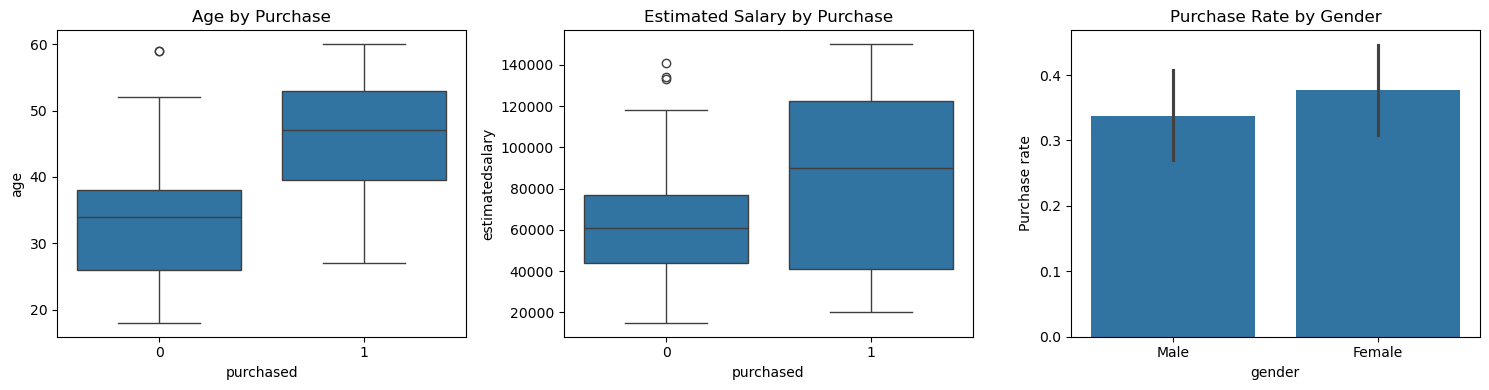

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.boxplot(data=df1, x='purchased', y='age', ax=axes[0])
axes[0].set_title('Age by Purchase')
sns.boxplot(data=df1, x='purchased', y='estimatedsalary', ax=axes[1])
axes[1].set_title('Estimated Salary by Purchase')
sns.barplot(data=df1, x='gender', y='purchased', ax=axes[2])
axes[2].set_xticks([0, 1], ['Male', 'Female'])
axes[2].set_ylabel('Purchase rate')
axes[2].set_title('Purchase Rate by Gender')
plt.tight_layout()
plt.show()

Buyers are clearly older and tend to have higher salaries. Gender shows only a small difference in purchase rate.

## 5. Train/Test Split and Cross-Validation

Scaling is placed **inside a pipeline**, so that during cross-validation the scaler is refit on each training fold only. This prevents information from the validation fold leaking into the scaler.

In [6]:
X = df1[['age', 'gender', 'estimatedsalary']]
y = df1['purchased']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y)

pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('logreg', LogisticRegression(max_iter=1000))
])

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
cv_res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=['accuracy', 'roc_auc', 'recall'])

print("Baseline model, 10-fold stratified CV on the training set")
print(f"Accuracy : {cv_res['test_accuracy'].mean():.4f} ± {cv_res['test_accuracy'].std():.4f}")
print(f"ROC AUC  : {cv_res['test_roc_auc'].mean():.4f} ± {cv_res['test_roc_auc'].std():.4f}")
print(f"Recall(1): {cv_res['test_recall'].mean():.4f} ± {cv_res['test_recall'].std():.4f}")

Baseline model, 10-fold stratified CV on the training set
Accuracy : 0.8344 ± 0.0344
ROC AUC  : 0.9287 ± 0.0271
Recall(1): 0.6856 ± 0.1312


## 6. Hyperparameter Tuning

The search covers the regularization strength `C` and `class_weight`. Balanced class weights can raise recall for the minority class (buyers).

The best model is chosen by **F1 score** for the Purchased class, which balances precision and recall at the actual decision threshold. ROC AUC is also recorded, but it is a poor selection criterion on its own here. ROC AUC barely changes across `C`, and selecting by it picks very strong regularization, which squeezes the predicted probabilities toward the class prior and causes most buyers to be missed.

In [7]:
param_grid = {
    'logreg__C': [0.01, 0.1, 1, 10, 100],
    'logreg__class_weight': [None, 'balanced'],
}

grid = GridSearchCV(pipe, param_grid, cv=cv, scoring={'f1': 'f1', 'roc_auc': 'roc_auc'}, refit='f1')
grid.fit(X_train, y_train)

grid_table = pd.DataFrame(grid.cv_results_)[['param_logreg__C', 'param_logreg__class_weight',
                                             'mean_test_f1', 'mean_test_roc_auc']]
print(grid_table.sort_values('mean_test_f1', ascending=False).round(4).to_string(index=False))
print('\nBest parameters :', grid.best_params_)
print(f'Best CV F1      : {grid.best_score_:.4f}')

best_model = grid.best_estimator_
best_cv = cross_validate(best_model, X_train, y_train, cv=cv, scoring=['accuracy', 'roc_auc', 'recall'])
print(f"Best model CV accuracy : {best_cv['test_accuracy'].mean():.4f}")
print(f"Best model CV recall(1): {best_cv['test_recall'].mean():.4f}")

 param_logreg__C param_logreg__class_weight  mean_test_f1  mean_test_roc_auc
            0.10                   balanced        0.7890             0.9300
            1.00                   balanced        0.7854             0.9287
           10.00                   balanced        0.7854             0.9292
          100.00                   balanced        0.7854             0.9292
            0.01                   balanced        0.7729             0.9301
           10.00                       None        0.7610             0.9283
          100.00                       None        0.7610             0.9283
            1.00                       None        0.7408             0.9287
            0.10                       None        0.7333             0.9292
            0.01                       None        0.5714             0.9301

Best parameters : {'logreg__C': 0.1, 'logreg__class_weight': 'balanced'}
Best CV F1      : 0.7890
Best model CV accuracy : 0.8438
Best model CV recall(1

## 7. Hold-out Test Evaluation

In [8]:
y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]

print(f"Test Accuracy : {accuracy_score(y_test, y_pred):.4f}")
print(f"Test ROC AUC  : {roc_auc_score(y_test, y_prob):.4f}")
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred, target_names=['Not purchased', 'Purchased']))

Test Accuracy : 0.8000


Test ROC AUC  : 0.9060

Confusion Matrix:
 [[41 10]
 [ 6 23]]

Classification Report:
                precision    recall  f1-score   support

Not purchased       0.87      0.80      0.84        51
    Purchased       0.70      0.79      0.74        29

     accuracy                           0.80        80
    macro avg       0.78      0.80      0.79        80
 weighted avg       0.81      0.80      0.80        80



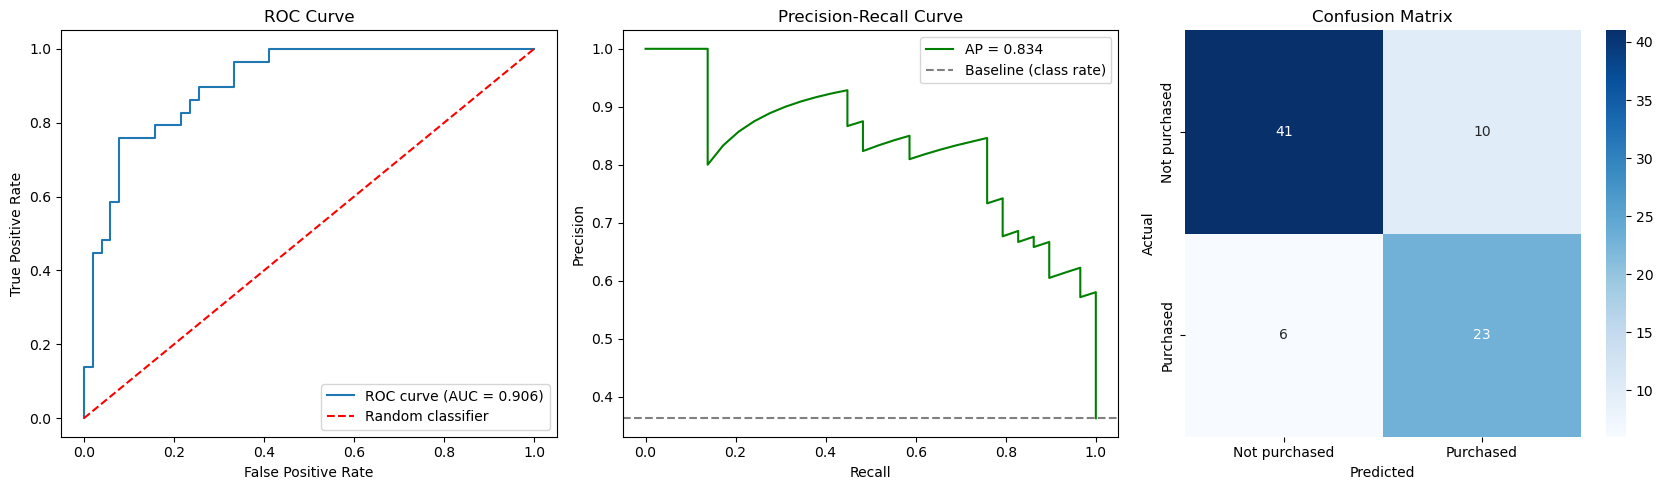

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# ROC curve
fpr, tpr, _ = roc_curve(y_test, y_prob)
axes[0].plot(fpr, tpr, label=f'ROC curve (AUC = {roc_auc_score(y_test, y_prob):.3f})')
axes[0].plot([0, 1], [0, 1], 'r--', label='Random classifier')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].set_title('ROC Curve')
axes[0].legend()

# Precision-recall curve
precision, recall, _ = precision_recall_curve(y_test, y_prob)
axes[1].plot(recall, precision, color='green',
             label=f'AP = {average_precision_score(y_test, y_prob):.3f}')
axes[1].axhline(y_test.mean(), color='gray', linestyle='--', label='Baseline (class rate)')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].set_title('Precision-Recall Curve')
axes[1].legend()

# Confusion matrix
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues', ax=axes[2],
            xticklabels=['Not purchased', 'Purchased'], yticklabels=['Not purchased', 'Purchased'])
axes[2].set_xlabel('Predicted')
axes[2].set_ylabel('Actual')
axes[2].set_title('Confusion Matrix')

plt.tight_layout()
plt.show()

## 8. Model Interpretation

Features are standardized, so each coefficient is the change in log-odds for a **one standard deviation** increase in that feature. Exponentiating a coefficient gives an **odds ratio**.

        Feature  Coefficient (log-odds per SD)  Odds Ratio per SD
            age                          1.532              4.626
estimatedsalary                          0.878              2.406
         gender                         -0.062              0.940


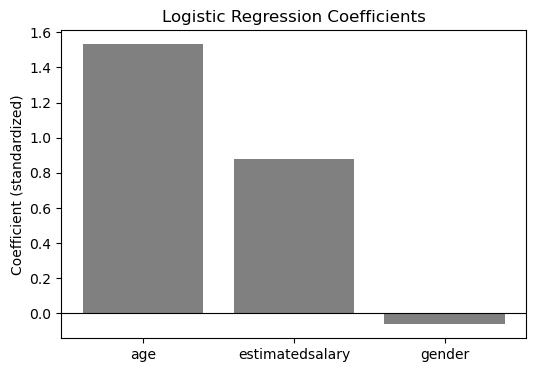

In [10]:
logreg = best_model.named_steps['logreg']
coef_df = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient (log-odds per SD)': logreg.coef_[0],
    'Odds Ratio per SD': np.exp(logreg.coef_[0]),
}).sort_values('Coefficient (log-odds per SD)', ascending=False)
print(coef_df.round(3).to_string(index=False))

plt.figure(figsize=(6, 4))
plt.bar(coef_df['Feature'], coef_df['Coefficient (log-odds per SD)'], color='gray')
plt.axhline(0, color='black', linewidth=0.8)
plt.ylabel('Coefficient (standardized)')
plt.title('Logistic Regression Coefficients')
plt.show()

## 9. Summary

In [11]:
summary = pd.DataFrame({
    'Metric': ['Accuracy', 'ROC AUC', 'Recall (Purchased)'],
    '10-fold CV (train)': [best_cv['test_accuracy'].mean(), best_cv['test_roc_auc'].mean(), best_cv['test_recall'].mean()],
    'Hold-out test': [accuracy_score(y_test, y_pred), roc_auc_score(y_test, y_prob),
                      ((y_pred == 1) & (y_test == 1)).sum() / (y_test == 1).sum()],
})
print(summary.round(4).to_string(index=False))

            Metric  10-fold CV (train)  Hold-out test
          Accuracy              0.8438         0.8000
           ROC AUC              0.9300         0.9060
Recall (Purchased)              0.8159         0.7931


## 10. Conclusion

| Metric | 10-fold CV (train) | Hold-out test |
|---|---|---|
| Accuracy | 0.844 | 0.800 |
| ROC AUC | 0.930 | 0.906 |
| Recall (Purchased) | 0.816 | 0.793 |

* **Selected model:** logistic regression with `C = 0.1` and balanced class weights, standardized inside a pipeline.
* **Age is the strongest driver.** Each standard deviation of age (about 10 years) multiplies the odds of purchase by about 4.6. Estimated salary is second (about 2.4× per SD). Gender has no meaningful effect (odds ratio ≈ 0.94).
* **Balanced class weights raised buyer recall** from about 0.69 (default model) to about 0.82 in cross-validation. The cost is some extra false positives, a sensible trade-off for targeting likely buyers.
* **Use the CV figure as the main estimate.** The test set has only 80 rows, so a single test score moves by several points depending on the split.